In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

In [2]:
# Load the original dataset
df = pd.read_csv("weatherAUS.csv")

# Check dataset dimensions
print("Dataset shape:", df.shape)

# Preview the first five rows
df.head()

Dataset shape: (145460, 23)


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


## Data Preparation and Train/Validation/Test Split

Before conducting EDA, we split the dataset into training, validation, and test sets. EDA will primarily be performed on the training set.

In [3]:
# Remove observations with missing target values
df_clean = df.dropna(subset=["RainTomorrow"]).copy()

# Separate predictors and target
X = df_clean.drop(columns=["RainTomorrow"])
y = df_clean["RainTomorrow"]

# Split into training (60%) and temporary (40%) sets
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.4,
    random_state=42,
    stratify=y
)

# Split temporary set equally into validation and test sets
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

# Verify dataset sizes
print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

Training set: (85315, 22)
Validation set: (28439, 22)
Test set: (28439, 22)


## Exploratory Data Analysis (EDA)

### Dataset Overview

We begin by examining the structure of the training dataset and generating some descriptive statistics.

In [4]:
# Examine the structure of the training dataset
print("Training dataset shape:", X_train.shape)

# Display feature names and data types
print("\nFeature data types:")
print(X_train.dtypes)

# Identify numerical and categorical features
numeric_cols = X_train.select_dtypes(include="number").columns
categorical_cols = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns

print("\nNumber of numerical features:", len(numeric_cols))
print("Number of categorical features:", len(categorical_cols))

# Check for duplicate observations
print("\nDuplicate rows:", X_train.duplicated().sum())

Training dataset shape: (85315, 22)

Feature data types:
Date                 str
Location             str
MinTemp          float64
MaxTemp          float64
Rainfall         float64
Evaporation      float64
Sunshine         float64
WindGustDir          str
WindGustSpeed    float64
WindDir9am           str
WindDir3pm           str
WindSpeed9am     float64
WindSpeed3pm     float64
Humidity9am      float64
Humidity3pm      float64
Pressure9am      float64
Pressure3pm      float64
Cloud9am         float64
Cloud3pm         float64
Temp9am          float64
Temp3pm          float64
RainToday            str
dtype: object

Number of numerical features: 16
Number of categorical features: 6

Duplicate rows: 0


In [5]:
# Summary statistics for numerical weather features
X_train.describe().round(2)

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
count,84931.00,85126.00,84490.00,48759.00,44540.00,79749.00,84505.00,83719.00,84240.00,83124.00,76940.00,76943.00,53126.00,50992.00,84766.00,83661.00
mean,12.17,23.22,2.34,5.49,7.61,39.95,13.97,18.63,68.85,51.52,1017.67,1015.28,4.44,4.50,16.97,21.67
std,6.41,7.13,8.51,4.25,3.78,13.61,8.89,8.82,19.06,20.82,7.10,7.04,2.88,2.72,6.51,6.95
min,-8.50,-4.10,0.00,0.00,0.00,6.00,0.00,0.00,1.00,0.00,982.30,977.10,0.00,0.00,-5.90,-5.10
25%,7.60,17.90,0.00,2.60,4.90,31.00,7.00,13.00,57.00,37.00,1013.00,1010.50,1.00,2.00,12.20,16.60
50%,12.00,22.60,0.00,4.80,8.40,39.00,13.00,19.00,70.00,52.00,1017.70,1015.30,5.00,5.00,16.70,21.10
75%,16.90,28.20,0.60,7.40,10.60,48.00,19.00,24.00,83.00,66.00,1022.40,1020.00,7.00,7.00,21.60,26.40
max,31.40,48.10,367.60,145.00,14.30,135.00,130.00,83.00,100.00,100.00,1041.00,1039.60,9.00,9.00,40.20,46.20


RainToday
No     65661
Yes    18829
NaN      825
Name: count, dtype: int64


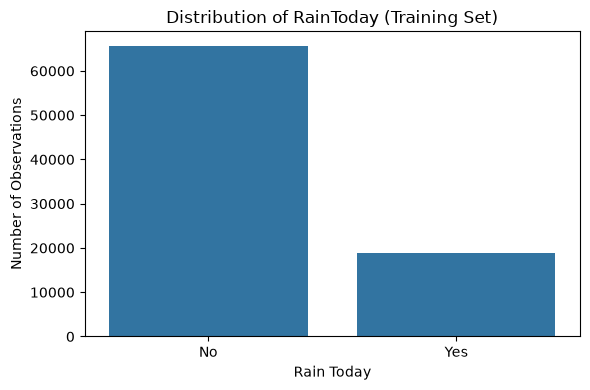

In [6]:
# Distribution of RainToday
print(X_train["RainToday"].value_counts(dropna=False))

plt.figure(figsize=(6, 4))

sns.countplot(
    data=X_train,
    x="RainToday",
    order=["No", "Yes"]
)

plt.title("Distribution of RainToday (Training Set)")
plt.xlabel("Rain Today")
plt.ylabel("Number of Observations")

plt.tight_layout()
plt.show()

**Interpretation:**

The training dataset contains 85,315 observations and 22 predictor variables, including 16 numerical variables and 6 string-valued variables. No duplicate rows were identified.

Descriptive statistics reveal variation in weather measurements, particularly rainfall, which has a median of 0 mm and a maximum of 367.6 mm. This suggests a highly right-skewed distribution.

The `RainToday` variable is also imbalanced, with 65,661 observations classified as "No" and 18,829 as "Yes", along with 825 missing values.

### 1. Target Variable Distribution

First, we examine the distribution of `RainTomorrow` in the training
dataset to identify potential class imbalance.

RainTomorrow counts:
RainTomorrow
No     66189
Yes    19126
Name: count, dtype: int64

RainTomorrow percentages:
RainTomorrow
No     77.58
Yes    22.42
Name: proportion, dtype: float64


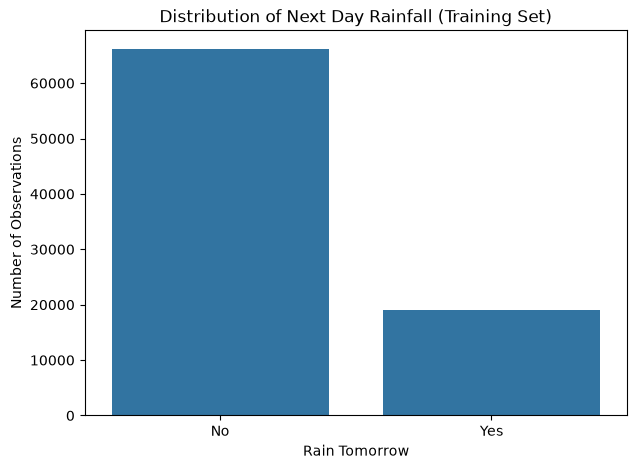

In [7]:
# Count observations for each target class
rain_counts = y_train.value_counts()
rain_percentages = y_train.value_counts(normalize=True) * 100

print("RainTomorrow counts:")
print(rain_counts)

print("\nRainTomorrow percentages:")
print(rain_percentages.round(2))

# Visualize the target distribution
plt.figure(figsize=(7, 5))

sns.countplot(x=y_train, order=["No", "Yes"])

plt.title("Distribution of Next Day Rainfall (Training Set)")
plt.xlabel("Rain Tomorrow")
plt.ylabel("Number of Observations")

plt.show()

**Interpretation:**

The target variable is imbalanced, with 77.58% of training observations classified as no rain and 22.42% as rain. A model that always predicts "No" would achieve ~77.58% training accuracy without correctly identifying any rainy days. Accuracy alone is not enough to evaluate model performance, and additional metrics such as precision, recall, and F1 score should be considered.

### 2. Missing Data Analysis

Next we'll examine the proportion of missing values across features in the training dataset to identify variables that might require imputation.

Sunshine         47.79
Evaporation      42.85
Cloud3pm         40.23
Cloud9am         37.73
Pressure9am       9.82
Pressure3pm       9.81
WindDir9am        7.13
WindGustDir       6.56
WindGustSpeed     6.52
WindDir3pm        2.70
Humidity3pm       2.57
Temp3pm           1.94
WindSpeed3pm      1.87
Humidity9am       1.26
RainToday         0.97
Rainfall          0.97
WindSpeed9am      0.95
Temp9am           0.64
MinTemp           0.45
MaxTemp           0.22
Location          0.00
Date              0.00
dtype: float64


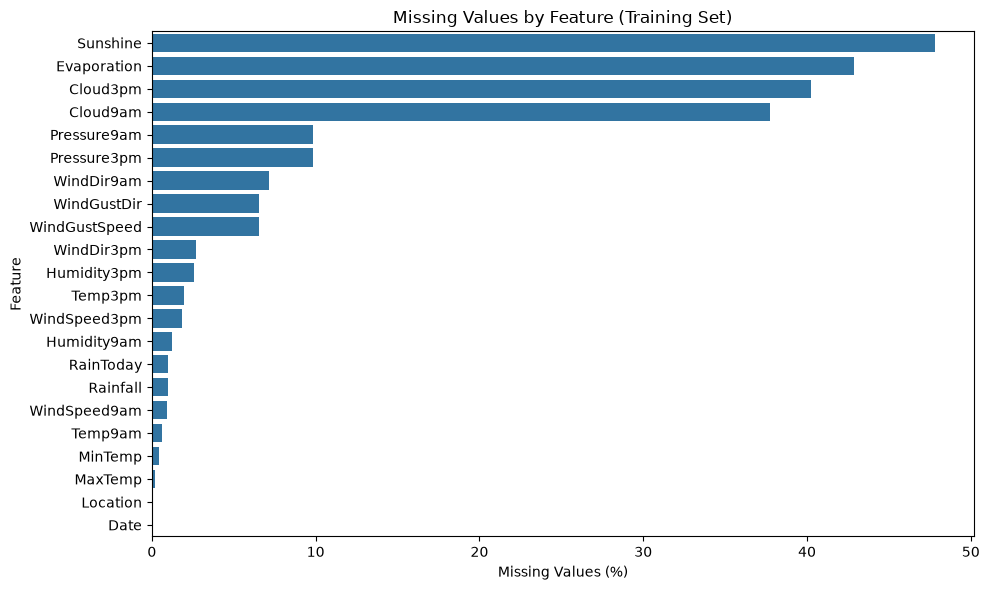

In [8]:
# Calculate missing values for each feature
missing_pct = X_train.isna().mean().sort_values(ascending=False) * 100

# Display missing percentages
print(missing_pct.round(2))

# Visualize missing values
plt.figure(figsize=(10, 6))

sns.barplot(
    x=missing_pct.values,
    y=missing_pct.index
)

plt.title("Missing Values by Feature (Training Set)")
plt.xlabel("Missing Values (%)")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

**Interpretation:**

Missing values are unevenly distributed across weather features. Sunshine (47.79%), Evaporation (42.85%), Cloud3pm (40.23%), and Cloud9am (37.73%) have a particularly high number of missing values, while most other variables have relatively few missing observations.


### 3. Numerical Feature Distributions

Next we'll examine the distributions of a few weather variables to identify skewness, potential outliers, and differences in scale that may affect model performance.

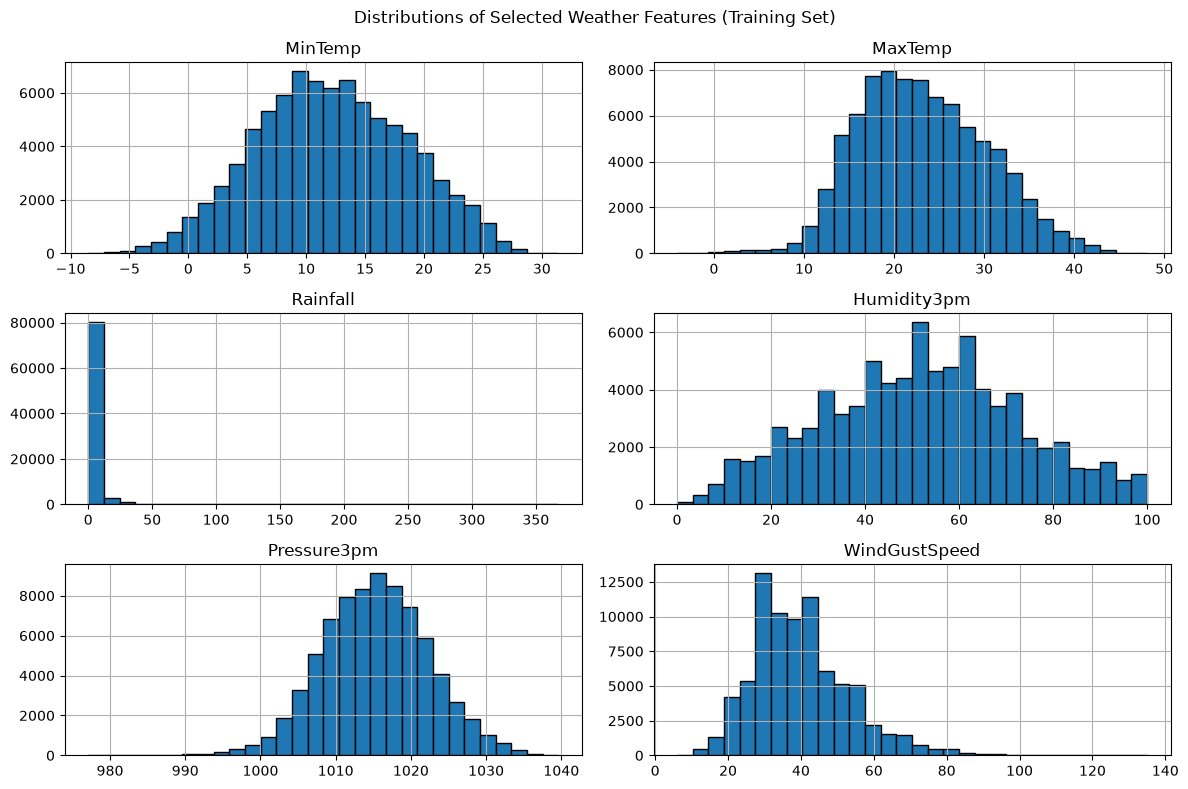

In [9]:
# Select numerical weather features
features = [
    "MinTemp",
    "MaxTemp",
    "Rainfall",
    "Humidity3pm",
    "Pressure3pm",
    "WindGustSpeed"
]

# Plot histograms
X_train[features].hist(
    bins=30,
    figsize=(12, 8),
    edgecolor="black"
)

plt.suptitle("Distributions of Selected Weather Features (Training Set)")
plt.tight_layout()
plt.show()

**Interpretation:**

The distributions of minimum temperature, maximum temperature, and afternoon atmospheric pressure are approximately normal, while rainfall and wind gust speed exhibit more right-skewed distributions.

Rainfall is particularly skewed, with most observations concentrated near zero and relatively few observations with high precipitation. A log transformation could be useful during preprocessing to reduce skewness.

The features also vary considerably in scale. Extreme weather measurements should not automatically be removed, because they could still represent meaningful weather events.

### 4. Weather Features and Next Day Rainfall

Next we'll compare the distributions of meteorological variables across the two target classes to identify potential relationships with next day rainfall.

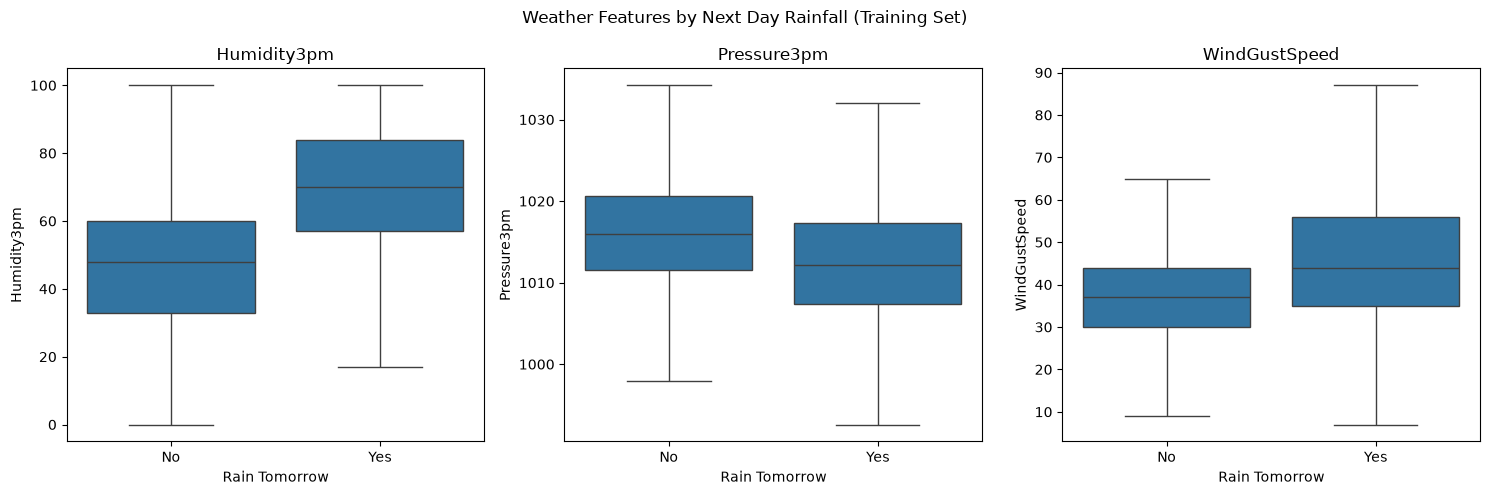

In [10]:
# Combine training features with the target variable for EDA
eda_df = X_train.copy()
eda_df["RainTomorrow"] = y_train

# Select features to compare
features_to_compare = [
    "Humidity3pm",
    "Pressure3pm",
    "WindGustSpeed"
]

# Create boxplots
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, feature in enumerate(features_to_compare):
    sns.boxplot(
        data=eda_df,
        x="RainTomorrow",
        y=feature,
        order=["No", "Yes"],
        ax=axes[i],
        showfliers=False
    )

    axes[i].set_title(feature)
    axes[i].set_xlabel("Rain Tomorrow")
    axes[i].set_ylabel(feature)

plt.suptitle("Weather Features by Next Day Rainfall (Training Set)")
plt.tight_layout()
plt.show()

**Interpretation:**

The distributions of these meteorological features differ depending on whether rainfall occurs the following day. Afternoon humidity shows the clearest separation, with median humidity approximately 70% for observations followed by rain compared with 47% for observations followed by no rain. Atmospheric pressure tends to be lower before rainy days, while wind gust speeds tend to be higher.

Although the distributions overlap, these patterns suggest that humidity, atmospheric pressure, and wind gust speed could be useful predictors of next day rainfall.

### 5. Geographic Variation in Next Day Rainfall

Now we'll examine the proportion of observations followed by rainfall across Australian weather stations to identify any geographic differences in rainfall.

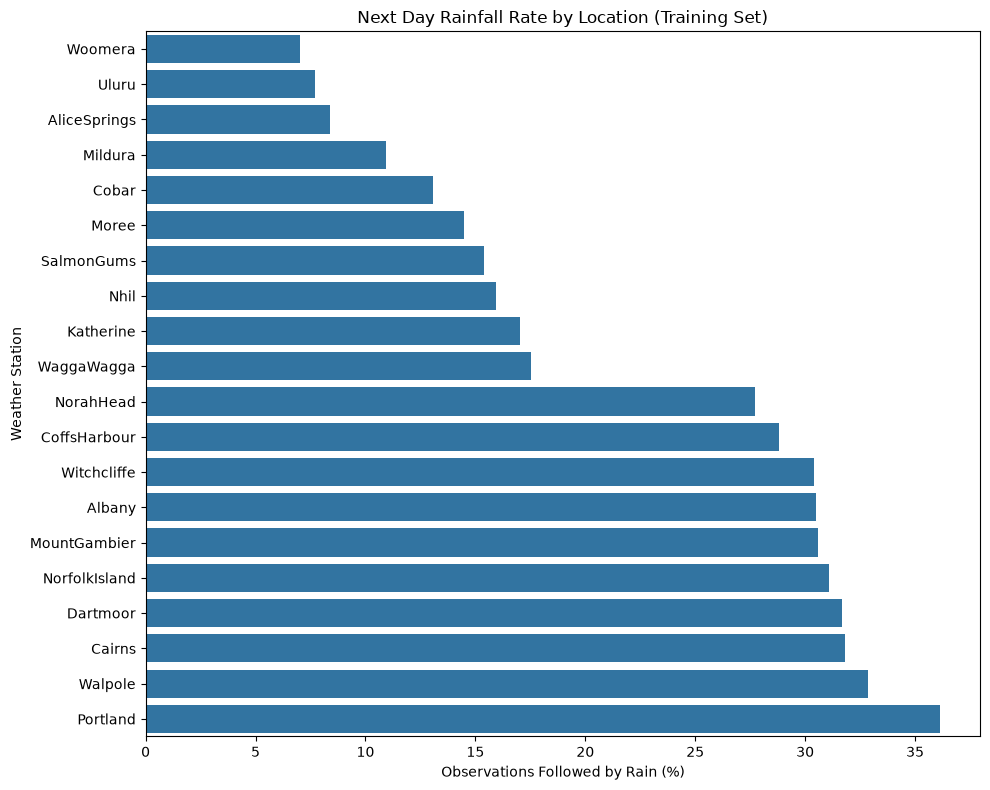

In [11]:
# Calculate next day rainfall rate for each location
location_rain = (
    eda_df.groupby("Location")["RainTomorrow"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values()
)

# Select locations with highest and lowest rainfall rates
top_bottom = pd.concat([
    location_rain.head(10),
    location_rain.tail(10)
]).sort_values()

# Plot rainfall rates by location
plt.figure(figsize=(10, 8))

sns.barplot(
    x=top_bottom.values,
    y=top_bottom.index
)

plt.title("Next Day Rainfall Rate by Location (Training Set)")
plt.xlabel("Observations Followed by Rain (%)")
plt.ylabel("Weather Station")

plt.tight_layout()
plt.show()

**Interpretation:**

Next day rainfall frequency varies substantially across weather stations in Australia. Portland has the highest observed rainfall rate (~36%), while Woomera has one of the lowest (~7%). The coastal locations exhibit relatively high rainfall rates, whereas more inland locations such as Alice Springs, Uluru, and Woomera have comparatively low rates.

These findings suggest that geographic location may be an important predictor of next day rainfall. However, there are some differences in observation periods and sample sizes across these stations which could affect that interpretation.

### 6. Seasonal Variation in Next Day Rainfall

Lastly we'll examine monthly differences in next day rainfall frequency to investigate seasonal patterns and check whether month of observation could be useful for prediction.

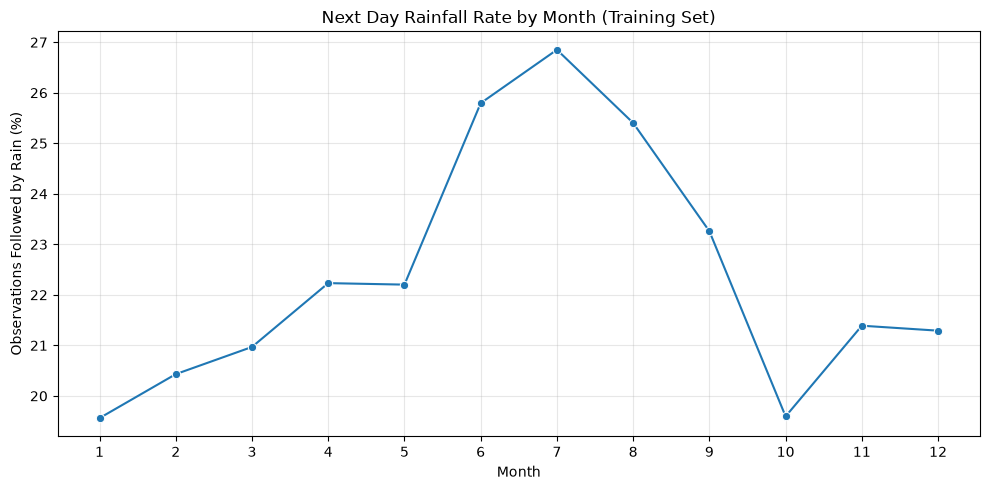

In [12]:
# Extract month from the observation date
eda_df["Month"] = pd.to_datetime(eda_df["Date"]).dt.month

# Calculate next day rainfall rate by month
monthly_rain = (
    eda_df.groupby("Month")["RainTomorrow"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

# Plot monthly rainfall rates
plt.figure(figsize=(10, 5))

sns.lineplot(
    x=monthly_rain.index,
    y=monthly_rain.values,
    marker="o"
)

plt.title("Next Day Rainfall Rate by Month (Training Set)")
plt.xlabel("Month")
plt.ylabel("Observations Followed by Rain (%)")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Interpretation:**

Next day rainfall frequency varies by month, which suggests a seasonal component to rainfall patterns. The highest rainfall rate occurs in July (~27%), while January and October have the lowest rates (~20%).

These findings support including seasonal information as a predictor. However, these results do aggregate observations across all weather stations which could potential mask differences in regional rainfall patterns.

### 7. Correlation Analysis

Finally, we'll examine correlations among numerical weather features to identify potential relationships and multicollinearity that could influence modeling.

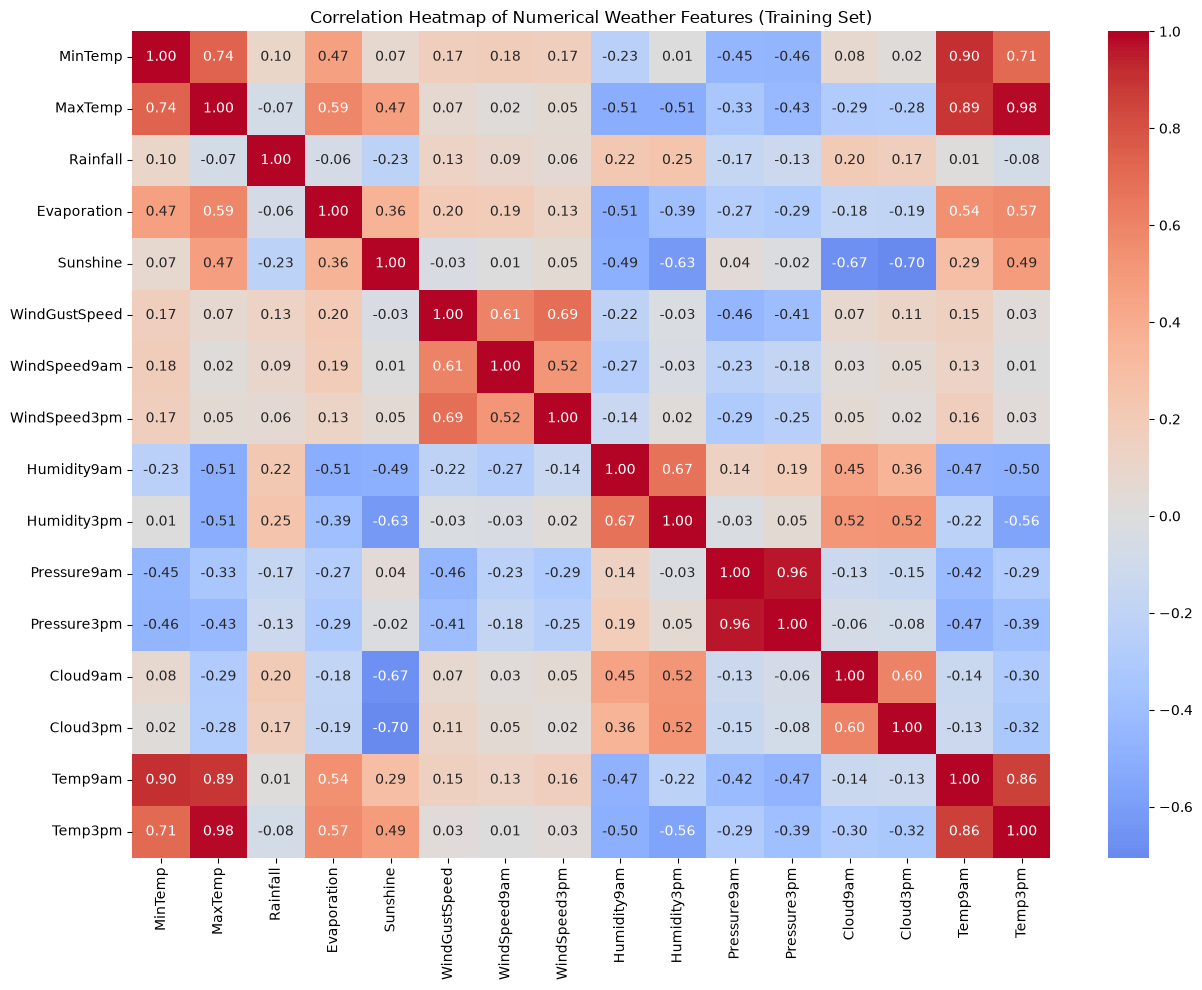

In [13]:
# Select numerical features from the training set
numeric_features = X_train.select_dtypes(include="number")

# Calculate correlations
corr_matrix = numeric_features.corr()

# Plot correlation heatmap
plt.figure(figsize=(13, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Weather Features (Training Set)")
plt.tight_layout()
plt.show()

**Interpretation:**

Several numerical weather features exhibit strong correlations so there may be potential redundancy among predictors. Maximum temperature and afternoon temperature are highly correlated (r=0.98), as well as morning and afternoon atmospheric pressure (r=0.96). Minimum temperature and morning temperature also show a strong positive correlation (r=0.90). Sunshine and afternoon cloud cover exhibit a strong negative correlation (r=-0.70), which is consistent with the expected relationship between cloudiness and sunlight.

These findings suggest that multicollinearity may be a consideration for logistic regression. These correlated features don't necessarily need to be removed but we will be sure to consider their relationships when interpreting model coefficients and features.

### Seasonal Rainfall Patterns by Location

Examine how monthly next day rainfall rates vary across weather stations to investigate whether seasonal patterns differ geographically.

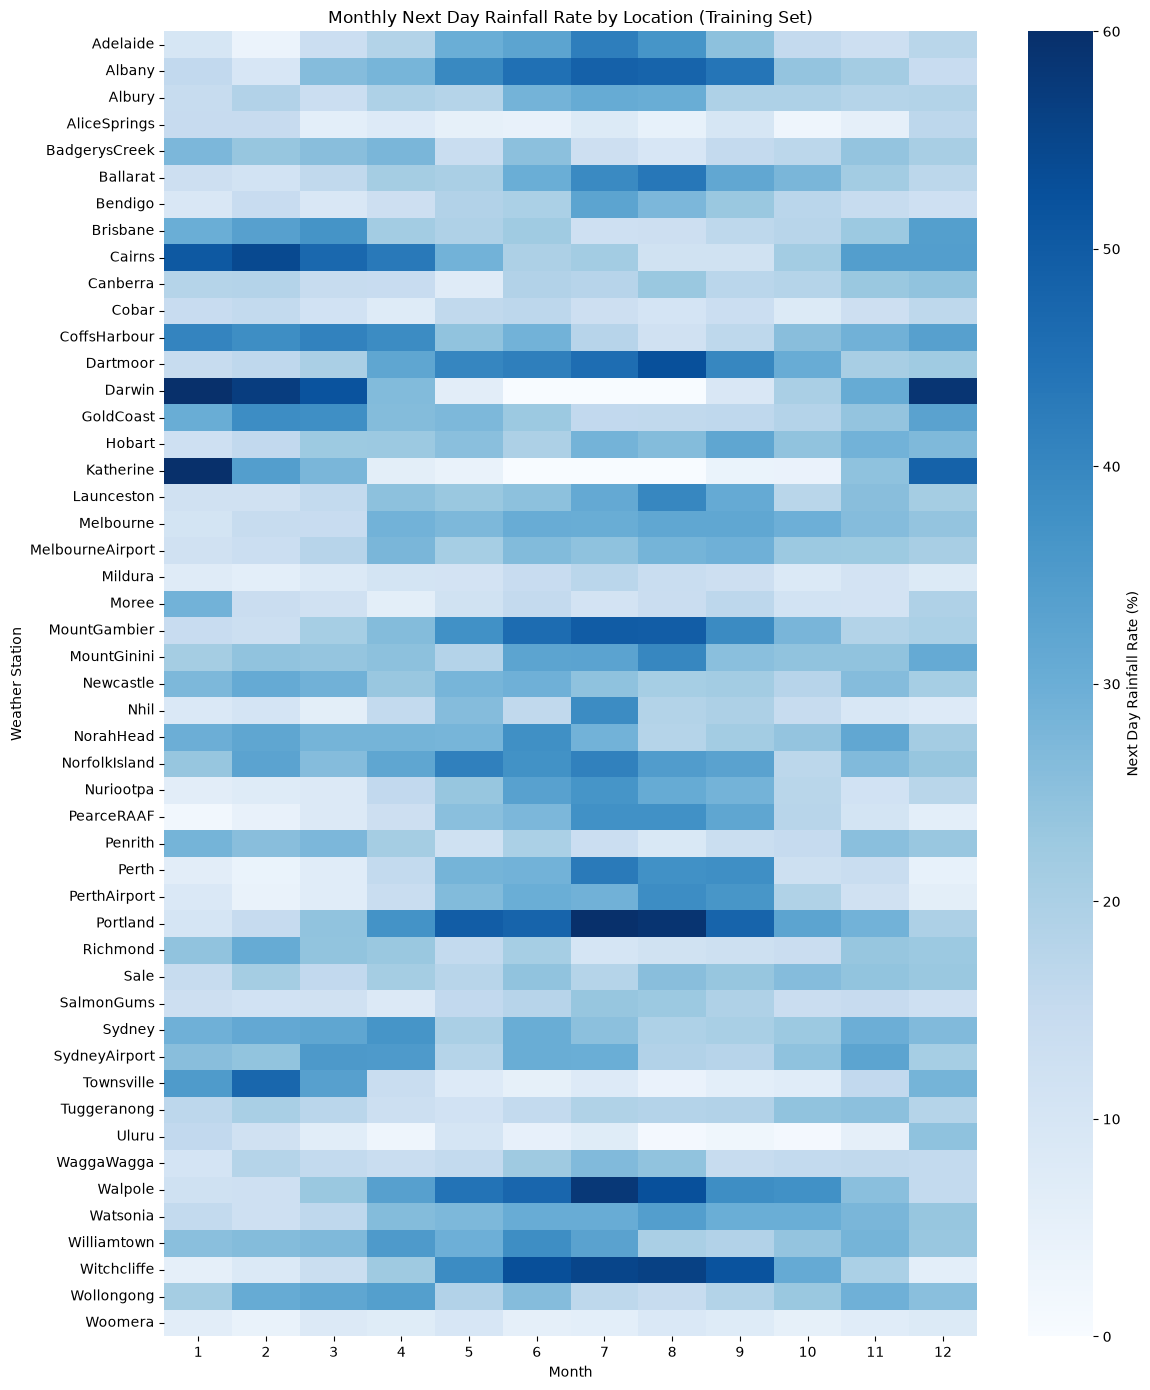

In [14]:
# Calculate next day rainfall rate by location and month
location_month_rain = (
    eda_df.groupby(["Location", "Month"])["RainTomorrow"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .unstack()
)

# Plot heatmap
plt.figure(figsize=(12, 14))

sns.heatmap(
    location_month_rain,
    cmap="Blues",
    vmin=0,
    vmax=60,
    cbar_kws={"label": "Next Day Rainfall Rate (%)"}
)

plt.title("Monthly Next Day Rainfall Rate by Location (Training Set)")
plt.xlabel("Month")
plt.ylabel("Weather Station")

plt.tight_layout()
plt.show()

**Interpretation:**

This heatmap reveals substantial geographic variation in seasonal rainfall patterns. More northern locations such as Darwin and Cairns exhibit higher next day rainfall frequencies during the summer in Australia (December–March), while southern and western locations such as Perth, Albany, and Portland generally experience higher rainfall frequencies during winter (June–August).

These contrasting patterns suggest that the relationship between month and next day rainfall might also depend on geographic location. This finding supports including both geographic and seasonal predictors in the models and suggests that interactions between these features may improve predictive performance. However, differences in observation counts should be considered when interpreting the results.